# Imports

In [1]:

import pandas as pd
import zipfile
import matplotlib.pyplot as plt
from pathlib import Path
from esaspoof.data import load_group, anomaly_mask, PROCESSED, load_processed, make_splits


# Look what we have

In [5]:
RAW = Path("../data/raw/ESA-Mission1")

for name in ["channels.csv", "labels.csv", "anomaly_types.csv"]:
    df = pd.read_csv(RAW / name)
    print(f"\n=== {name} shape={df.shape}")
    print(df.head())


=== channels.csv shape=(76, 5)
     Channel    Subsystem    Physical Unit  Group Target
0  channel_1  subsystem_1  physical_unit_1      1     NO
1  channel_2  subsystem_1  physical_unit_1      1     NO
2  channel_3  subsystem_1  physical_unit_1      1     NO
3  channel_4  subsystem_1  physical_unit_2      2     NO
4  channel_5  subsystem_1  physical_unit_2      2     NO

=== labels.csv shape=(3589, 4)
     ID     Channel                 StartTime                   EndTime
0  id_1  channel_12  2004-12-01T20:42:15.429Z  2004-12-08T22:55:45.429Z
1  id_1  channel_13  2004-12-01T20:42:15.429Z  2004-12-08T22:55:45.429Z
2  id_1  channel_14  2004-12-01T20:43:45.429Z  2004-12-02T02:57:15.429Z
3  id_1  channel_15  2004-12-01T20:45:00.429Z  2004-12-02T02:58:45.429Z
4  id_1  channel_16  2004-12-01T20:43:45.429Z  2004-12-16T16:52:30.429Z

=== anomaly_types.csv shape=(200, 7)
     ID    Class    Subclass    Category Dimensionality Locality       Length
0  id_1  class_6  subclass_1  Rare Event   Mul

In [6]:
files = sorted((RAW / "channels").iterdir())
print(len(files), "files")
print([f.name for f in files[:5]])

76 files
['channel_1.zip', 'channel_10.zip', 'channel_11.zip', 'channel_12.zip', 'channel_13.zip']


# Look inside the data

In [7]:
channels = pd.read_csv(RAW / "channels.csv")
print(channels.groupby(["Subsystem", "Group"])["Channel"].apply(list).to_string())
print("\nTarget counts:\n", channels["Target"].value_counts())

Subsystem    Group
subsystem_1  1                        [channel_1, channel_2, channel_3]
             2        [channel_4, channel_5, channel_6, channel_7, c...
             14                    [channel_61, channel_62, channel_63]
             17                    [channel_67, channel_68, channel_69]
subsystem_3  11                                [channel_53, channel_55]
             12                                [channel_54, channel_56]
             18       [channel_70, channel_71, channel_72, channel_7...
subsystem_5  8        [channel_41, channel_42, channel_43, channel_4...
subsystem_6  3        [channel_12, channel_13, channel_19, channel_2...
             4        [channel_14, channel_21, channel_29, channel_3...
             5        [channel_17, channel_18, channel_25, channel_2...
             6        [channel_16, channel_24, channel_32, channel_3...
             7        [channel_15, channel_22, channel_23, channel_3...
             9                     [channel_4

In [8]:
z = zipfile.ZipFile(RAW / "channels" / "channel_44.zip")
print(z.namelist())

['channel_44']


In [9]:
df = pd.read_pickle(RAW / "channels" / "channel_44.zip")
print(type(df))
print(df.head())
print(df.shape, df.index.min(), df.index.max())

<class 'pandas.DataFrame'>
                         channel_44
datetime                           
2000-01-01 00:00:16.353    0.799178
2000-01-01 00:00:46.353    0.809411
2000-01-01 00:01:08.853    0.793667
2000-01-01 00:01:16.353    0.807050
2000-01-01 00:01:46.353    0.807837
(15381169, 1) 2000-01-01 00:00:16.353000 2013-12-31 23:59:39.657000


# Build the dataset

In [11]:
group = channels.loc[channels["Group"] == 8, "Channel"].tolist()
print(group)

['channel_41', 'channel_42', 'channel_43', 'channel_44', 'channel_45', 'channel_46']


In [12]:
df = load_group(group)  # takes a minute, it reads ~15M rows per channel
mask = anomaly_mask(df.index, group)

print(df.shape)
print("NaN fraction per channel:\n", df.isna().mean())
print("anomalous fraction per channel:\n", mask.mean())

df.to_parquet(PROCESSED / "group8_10min.parquet")
mask.to_parquet(PROCESSED / "group8_mask.parquet")

(736416, 6)
NaN fraction per channel:
 channel_41    0.000049
channel_42    0.000049
channel_43    0.000049
channel_44    0.000049
channel_45    0.000049
channel_46    0.000049
dtype: float64
anomalous fraction per channel:
 channel_41    0.007560
channel_42    0.007564
channel_43    0.007599
channel_44    0.007594
channel_45    0.007553
channel_46    0.007569
dtype: float64


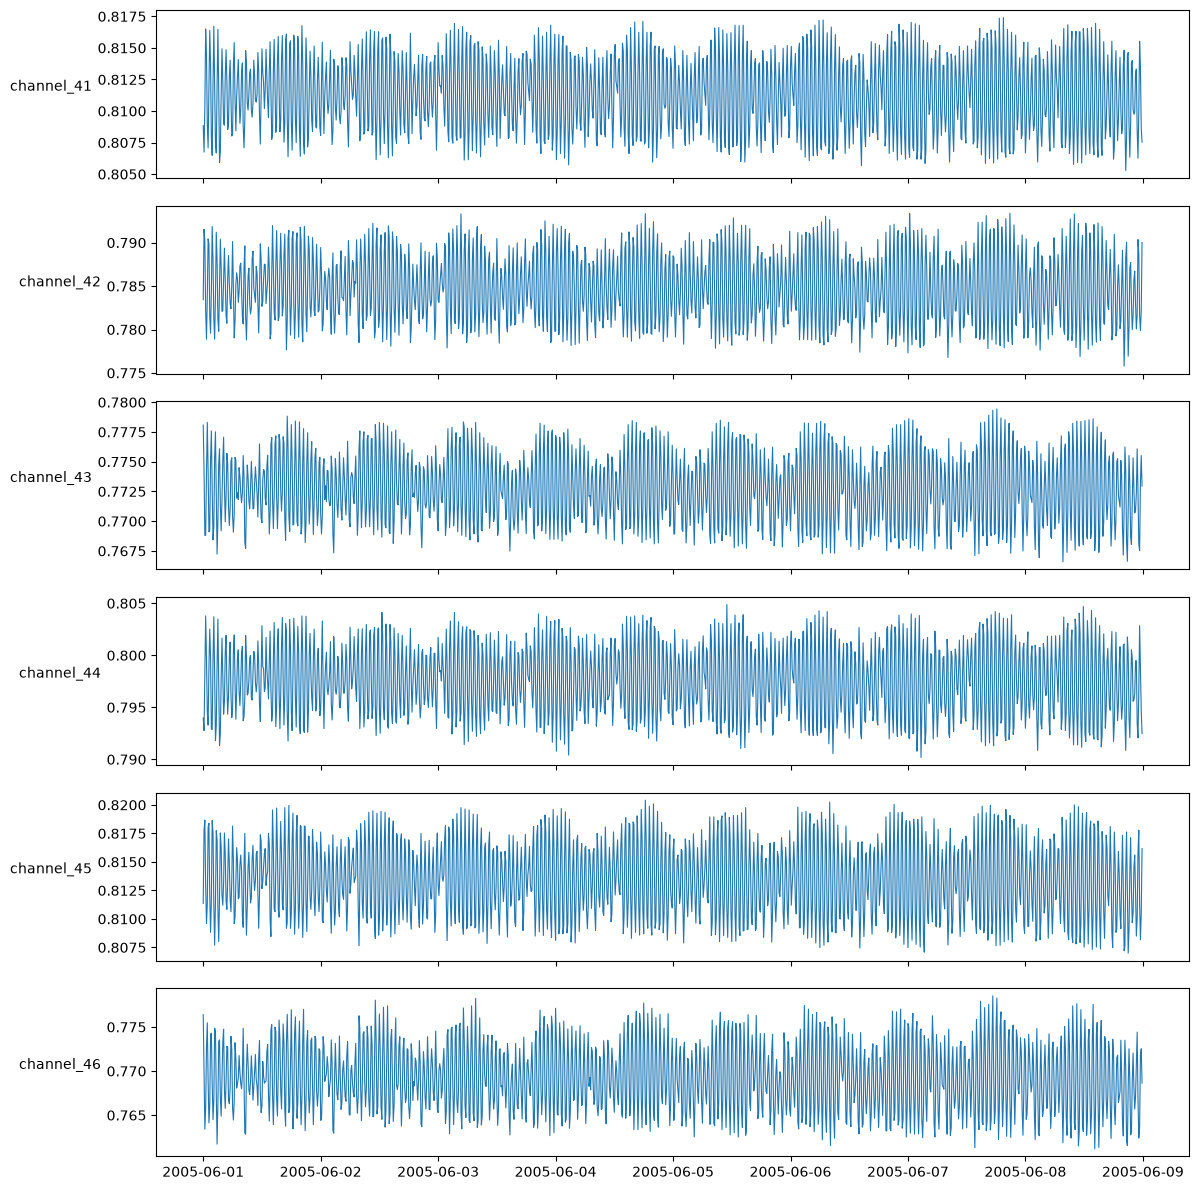

In [13]:
import matplotlib.pyplot as plt

week = df.loc["2005-06-01":"2005-06-08"]
fig, axes = plt.subplots(len(group), 1, figsize=(12, 2 * len(group)), sharex=True)
for ax, ch in zip(axes, group):
    ax.plot(week.index, week[ch], lw=0.8)
    ax.fill_between(week.index, week[ch].min(), week[ch].max(),
                    where=mask.loc[week.index, ch] == 1, color="red", alpha=0.2)
    ax.set_ylabel(ch, rotation=0, ha="right")
plt.tight_layout()

In [14]:
print(df.corr().round(2))

            channel_41  channel_42  channel_43  channel_44  channel_45  \
channel_41        1.00        0.96        0.91        0.84        0.97   
channel_42        0.96        1.00        0.91        0.80        1.00   
channel_43        0.91        0.91        1.00        0.76        0.91   
channel_44        0.84        0.80        0.76        1.00        0.81   
channel_45        0.97        1.00        0.91        0.81        1.00   
channel_46        0.97        0.96        0.93        0.80        0.96   

            channel_46  
channel_41        0.97  
channel_42        0.96  
channel_43        0.93  
channel_44        0.80  
channel_45        0.96  
channel_46        1.00  


# Look at the real anomalies

In [15]:
any_anom = mask.max(axis=1)
starts = any_anom.diff().fillna(any_anom.iloc[0]).eq(1)
event_id = starts.cumsum().where(any_anom == 1)

events = any_anom.index.to_series().groupby(event_id).agg(["min", "max"])
events["duration"] = events["max"] - events["min"]

print(len(events), "events")
print(events["duration"].describe())
print(events["min"].dt.year.value_counts().sort_index())

54 events
count                           54
mean     0 days 17:10:22.222222222
std      2 days 01:31:29.074858322
min                0 days 00:00:00
25%                0 days 00:00:00
50%                0 days 00:00:00
75%                0 days 14:02:30
max               13 days 18:00:00
Name: duration, dtype: object
min
2000    5
2002    4
2003    3
2004    2
2005    4
2006    4
2007    5
2008    3
2009    6
2010    5
2011    4
2012    3
2013    6
Name: count, dtype: int64


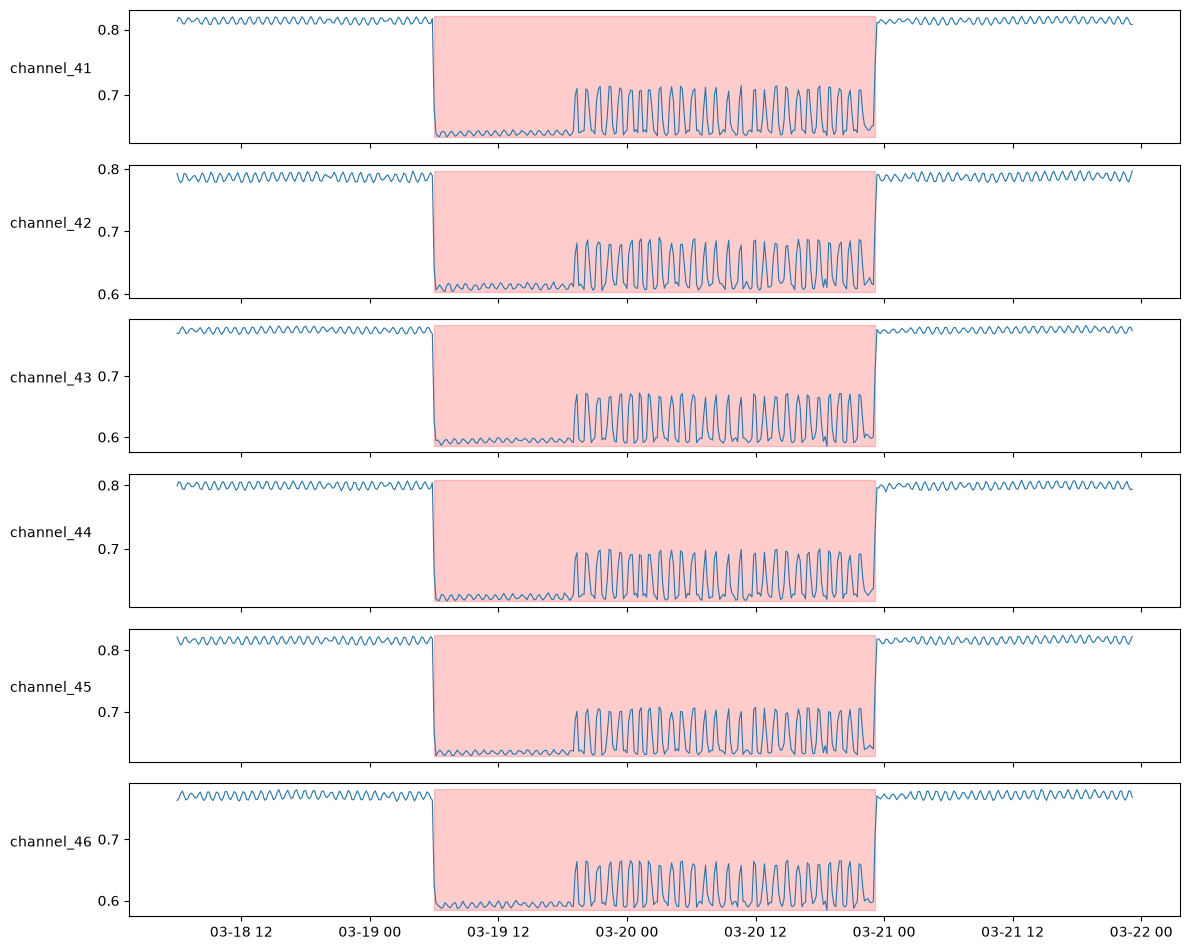

In [16]:
def plot_window(start, end, pad="1D"):
    w = df.loc[pd.Timestamp(start) - pd.Timedelta(pad): pd.Timestamp(end) + pd.Timedelta(pad)]
    fig, axes = plt.subplots(len(group), 1, figsize=(12, 1.6 * len(group)), sharex=True)
    for ax, ch in zip(axes, group):
        ax.plot(w.index, w[ch], lw=0.8)
        ax.fill_between(w.index, w[ch].min(), w[ch].max(),
                        where=mask.loc[w.index, ch] == 1, color="red", alpha=0.2)
        ax.set_ylabel(ch, rotation=0, ha="right")
    plt.tight_layout()

plot_window(*events.iloc[0][["min", "max"]])

In [2]:
df, mask = load_processed()
splits, (mu, sigma) = make_splits(df, mask)

for name, (x, m) in splits.items():
    print(f"{name:5s} {x.shape}  mean={x.values.mean():+.2f}  std={x.values.std():.2f}  anomalous={m.values.mean():.4f}")

train (420768, 6)  mean=-0.16  std=2.93  anomalous=0.0073
val   (105264, 6)  mean=-1.95  std=11.09  anomalous=0.0207
test  (210384, 6)  mean=-0.65  std=0.83  anomalous=0.0016
